In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

Note: you may need to restart the kernel to use updated packages.


# Oscillator Tracking — a Progressive Guide

## The Complete Picture

Every oscillator model in this notebook estimates the same object: a **phasor**
`ψ = Re + i·Im`. The phasor represents one spectral line.

The models differ in two ways:
- Which frame the phasor lives in.
- How the signal enters the filter.

The table below compares the four oscillator models.

| model | input | demodulate? | frame | `F` | `H` | best for |
|---|---|---|---|---|---|---|
| `AnalyticOscillatorModel` | analytic `[re, im]` | yes (rotate signal) | **rotating** | `expm(Δω)` | identity | the rotating-frame **building block** / teaching example |
| `OscillatorModel` | **real** | yes — Hilbert transform inside `preprocess` | **rotating** | `expm(Δω)` | identity | **weak, narrowband** lines (for example violin modes) |
| `PhasorOscillatorModel` | **real** | **no** | **lab** | `I` | `H(t)=[cos ωt, −sin ωt]` | **strong, wide-spread** lines |
| `PowerGridStateModel` | **real** | **no** | **lab** | `I` | `H(t)` | mains harmonics (see notebook 03) |

This notebook covers the **rotating-frame family**: `AnalyticOscillatorModel`, then
`OscillatorModel`, then `HarmonicOscillatorModel` and `InharmonicOscillatorModel`. It
builds up from first principles to a full KAGRA-style violin-mode subtraction.
Notebook 03 covers the lab-frame family.


---
## Step 1 — Lab Frame vs Rotating Frame

This is the most important concept in the oscillator family. Both frames track the
same phasor. They differ only in **where the carrier rotation sits**.

### Lab Frame: Carrier in `H(t)`

In the lab frame, you observe the raw signal directly: `x(t) = A cos(2π f₀ t + φ)`.

The phasor is `[Re, Im] = [A cosφ, −A sinφ]`. This phasor stays constant for a steady
sinusoid.

The observation map `H(t) = [cos ω₀t, −sin ω₀t]` oscillates at the carrier frequency
instead. So `F = I`: the phasor does not evolve. The carrier lives in `H(t)`. The lab
frame needs no demodulation. You feed in the real signal directly.

### Rotating Frame: Carrier in `F`

In the rotating frame, you mentally rotate together with the signal at the carrier
frequency `fc`. Two cases follow:
- If `f0 = fc`, the mode appears as a **DC constant**. This is the lock-in amplifier
  limit.
- If `f0 ≠ fc`, the mode **precesses slowly** at the detuning frequency
  `Δf = f0 − fc`.

The demodulation step multiplies the signal by `e^{−iω_c t}`. This step moves the
carrier out of the signal and into `F = expm(Δω·dt)`. Then `H = identity`: you
observe the envelope directly.

After demodulation, you can **decimate** the signal, because only the slowly-varying
envelope matters. This approach works best for **weak, narrowband** lines, where
noise dominates the signal.

### Why the Frame Choice Matters

| | Lab frame | Rotating frame |
|---|---|---|
| Input | real signal | real signal (Hilbert transform applied internally) |
| Carrier | in `H(t)` | in `F = expm(Δω)` |
| `F` | `I` (phasor constant) | `expm(Δω·dt)` (precession) |
| `H` | `[cos ωt, −sin ωt]` (time-varying) | `I` (identity, constant) |
| Multi-mode coupling | all modes share one measurement (no leakage) | each window demodulates independently |
| Decimation | no | yes (the envelope is slow) |
| Best for | strong, wide-spread lines | weak, narrowband lines |

The animation below shows the **same 180 Hz sinusoid** in both frames.


In [2]:
from scipy.signal import hilbert
from kalman.helpers import animate

# Fixed parameters — long enough to trace a full precession circle
_fs_demo, _T_demo = 4096.0, 10.0
_fc_demo, _df_demo, _phi_demo = 180.0, 0.1, np.pi / 6   # Δf=0.1 Hz → period 10 s

f0 = _fc_demo + _df_demo
A  = 1.0
N  = int(_T_demo * _fs_demo)
t  = np.arange(N) / _fs_demo
x  = A * np.cos(2 * np.pi * f0 * t + _phi_demo)
analytic_signal = hilbert(x)
psi = analytic_signal * np.exp(-1j * 2 * np.pi * _fc_demo * t)

true_re =  A * np.cos(_phi_demo)
true_im = -A * np.sin(_phi_demo)

# Animation: 30 frames, time cursor sweeps 0 → T
n_frames = 30
_stride  = max(1, N // 2000)           # cap lab-frame line to ~2000 pts
frame_idx = np.linspace(200, N - 1, n_frames, dtype=int)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle(
    f"Lab frame vs Rotating frame  (Δf={_df_demo} Hz, T={_T_demo:.0f} s, φ=30°)",
    fontweight="bold")

axes[0].set_title("Lab frame: raw signal x(t)")
axes[0].set_xlabel("t [ms]"); axes[0].set_ylabel("amplitude")
axes[0].axhline(0, color="gray", lw=0.5)
axes[0].set_xlim(0, _T_demo * 1e3); axes[0].set_ylim(-1.15, 1.15)

axes[1].set_title(f"Rotating frame: envelope ψ (fc={_fc_demo} Hz)")
axes[1].set_xlabel("t [ms]")
axes[1].axhline(0, color="gray", lw=0.5)
axes[1].set_xlim(0, _T_demo * 1e3); axes[1].set_ylim(-1.15, 1.15)

axes[2].plot(true_re, true_im, "*", ms=14, color="gold", zorder=5,
             label=f"true phasor\n[{true_re:.2f}, {true_im:.2f}]")
axes[2].axhline(0, color="gray", lw=0.5); axes[2].axvline(0, color="gray", lw=0.5)
axes[2].set_aspect("equal")
axes[2].set_xlabel(r"Re $\psi$"); axes[2].set_ylabel(r"Im $\psi$")
axes[2].set_xlim(-1.3, 1.3); axes[2].set_ylim(-1.3, 1.3)

line_lab,     = axes[0].plot([], [], color="steelblue",  lw=0.8)
line_re,      = axes[1].plot([], [], color="darkorange", lw=1.5, label="Re ψ")
line_im,      = axes[1].plot([], [], color="navy",       lw=1.5, label="Im ψ")
line_phasor,  = axes[2].plot([], [], color="purple",     lw=1.5)
point_start,  = axes[2].plot([], [], "o", ms=8, color="green",  zorder=4, label="start")
point_end,    = axes[2].plot([], [], "s", ms=7, color="purple", zorder=4, label="end")

axes[1].legend(fontsize=9)
axes[2].legend(fontsize=8)
fig.tight_layout()

def _draw(frame):
    k = frame_idx[frame]
    line_lab.set_data(t[:k:_stride] * 1e3, x[:k:_stride])
    line_re.set_data(t[:k] * 1e3, psi.real[:k])
    line_im.set_data(t[:k] * 1e3, psi.imag[:k])
    line_phasor.set_data(psi.real[:k], psi.imag[:k])
    point_start.set_data([psi.real[0]],   [psi.imag[0]])
    point_end.set_data(  [psi.real[k-1]], [psi.imag[k-1]])
    axes[2].set_title(f"Phase space  (t = {t[k]*1e3:.0f} ms)")
    return line_lab, line_re, line_im, line_phasor, point_start, point_end

animate(fig, _draw, frames=n_frames, interval=60)


---
## Step 2 — The Rotating-Frame Building Block: `AnalyticOscillatorModel`

`AnalyticOscillatorModel` tracks one mode in the rotating frame. It is the basic
building block of the family.

The model expects a 2-column analytic signal `[real, imag]`. You can create this
signal with `scipy.signal.hilbert`. The model tracks the slowly-varying envelope
`ψ = [Re, Im]`.

Two parameters set the frame, both in Hz:
- `f0`: the resonance frequency.
- `fc`: the carrier frequency.

For backward compatibility, the model still accepts `w0` and `wc` in rad/s.

The model applies **pre/post symmetry**:
- `preprocess` rotates the analytic input into the rotating frame.
- `postprocess` rotates the result back to the lab frame.

So `sample().zk` is analytic in the lab frame. You can filter it directly with
`model.filter(sample.zk)`.

Two cases below show the envelope behavior:
- **Case A — locked carrier (`fc = f0`)**: the envelope is DC. This is the lock-in
  mode.
- **Case B — detuned carrier (`fc ≠ f0`)**: the envelope precesses at the detuning
  frequency `Δf = f0 − fc`.


In [3]:
from kalman.apps.resonators.oscillators import AnalyticOscillatorModel
from IPython.display import display

f0_hz = 10.0    # resonance in Hz
fs_a  = 256.0
T_a   = 32.0

# Case A: locked carrier — envelope is DC
model_A = AnalyticOscillatorModel("locked", fs=fs_a, f0=f0_hz, fc=f0_hz,
                                   Q=10000, measurement_uncertainty=2.0,
                                   process_uncertainty=0.01, random_seed=42)
model_A.initial_state([10, 0])
sample_A = model_A.sample(T_a)
record_A = model_A.filter(sample_A, smooth=True, reset=True,
                          preprocess=True, postprocess=False)

# Case B: detuned carrier — slow precession
fc_b = 8.0
model_B = AnalyticOscillatorModel("detuned", fs=fs_a, f0=f0_hz, fc=fc_b,
                                   Q=10000, measurement_uncertainty=2.0,
                                   process_uncertainty=0.01, random_seed=42)
model_B.initial_state([10, 0])
sample_B = model_B.sample(T_a)
record_B = model_B.filter(sample_B, smooth=True, reset=True,
                          preprocess=True, postprocess=False)

print(f"f0 = {f0_hz} Hz,  fc_A = {f0_hz} Hz (locked),  fc_B = {fc_b} Hz (detuned)")
print(f"Δf_B = {f0_hz - fc_b:.1f} Hz  →  precession period ≈ {1/(f0_hz - fc_b):.2f} s")

# Signature plots — interactive time-cursor player
display(model_A.plot(record_A, sample=sample_A, interactive=True))   # lock-in: flat DC envelope
display(model_B.plot(record_B, sample=sample_B, interactive=True))   # detuned: precessing circle


f0 = 10.0 Hz,  fc_A = 10.0 Hz (locked),  fc_B = 8.0 Hz (detuned)
Δf_B = 2.0 Hz  →  precession period ≈ 0.50 s


ModuleNotFoundError: No module named 'kalman.apps.resonators.framework'

---
## Step 3 — One Analysis Window: `OscillatorModel`

`OscillatorModel` takes a **real** signal and one analysis window `[fc ± dfc]`.

The model processes the signal in four steps:
1. Heterodyne the signal to baseband (shift the carrier to zero frequency).
2. Downsample with `resample_poly`. This step includes anti-aliasing filtering.
3. Run the Kalman filter at the decimated rate `4·dfc`.
4. Upsample the phasor estimate to reconstruct the signal.

The signal flow diagram:
```
real strain ──► ×e^{-jωc·t} ──► resample_poly ↓ ──► Kalman [Re,Im] ──► resample_poly ↑ ──► ×e^{+jωc·t} ──► real band out
              heterodyne          downsample            decimated              upsample           remodulate
```

The Kalman state `xk` lives at the **decimated rate** `fs_dec = 4·dfc`. When you plot
`amplitudes(record)`, use `np.linspace(0, T, len(amp))` as the time axis.
`reconstruct(record)` always returns the signal at the **original rate**.


n=2, m=2 | in-band frequencies: [180.1] Hz
original N=32768, decimated N_dec=160, fs_dec=20.0 Hz
record.zk shape: (160, 2)  — real reconstruction at original rate
reconstruct shape: (32768,)  — real band upsampled to original rate


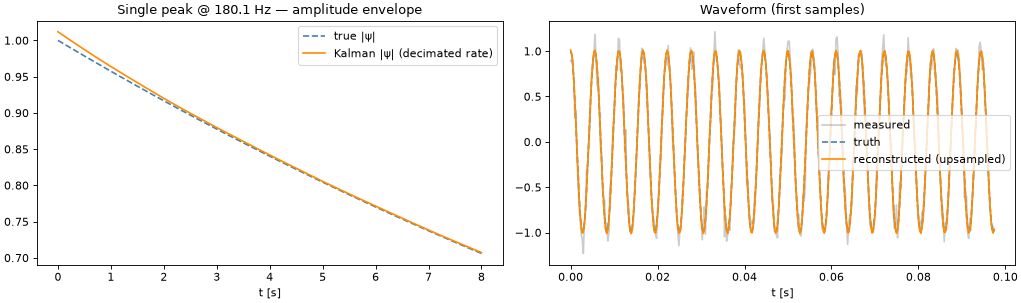

In [ ]:
from kalman.apps.resonators.oscillators import OscillatorModel
from numpy.fft import rfft, rfftfreq

fs, T = 4096.0, 8.0
N = int(T * fs)
t = np.arange(N) / fs
f1, amp1, q1 = 180.1, 1.0, 1.3e4
decay_time1 = q1 / (np.pi * f1)
clean  = amp1 * np.exp(-t / decay_time1) * np.cos(2 * np.pi * f1 * t)
strain = clean + 0.1 * np.random.randn(N)

model_single = OscillatorModel("mode", [f1], fc=f1, dfc=5.0, Q=q1, fs=fs,
                                measurement_uncertainty=0.1, process_uncertainty=1e-4)
rec   = model_single.filter(strain, smooth=True)
amp   = model_single.amplitudes(rec)[:, 0]      # shape (N_dec,) — state at decimated rate
recon = model_single.reconstruct(rec)           # shape (N,) — upsampled real band signal

# Decimated time axis for state quantities
t_dec = np.linspace(0, T, len(amp))

# Shared ASD (amplitude spectral density) helper, reused by later cells.
# A Hann window shows real spectral content, not a rectangular window's leakage skirt.
freq_axis   = rfftfreq(N, 1 / fs)
hann_window = np.hanning(N)
asd_norm    = 2.0 / (np.sum(hann_window) * np.sqrt(fs / N))

def asd(x):
    return np.abs(rfft(x * hann_window)) * asd_norm

print(f"n={model_single.n}, m={model_single.m} | in-band frequencies: {np.round(model_single.frequencies, 2)} Hz")
print(f"original N={N}, decimated N_dec={len(amp)}, fs_dec={model_single.fs:.1f} Hz")
print(f"record.zk shape: {np.asarray(rec.zk).shape}  — real reconstruction at original rate")
print(f"reconstruct shape: {recon.shape}  — real band upsampled to original rate")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(t, amp1 * np.exp(-t / decay_time1), "--", color="steelblue", label="true |ψ|")
axes[0].plot(t_dec, amp, color="darkorange", label="Kalman |ψ| (decimated rate)")
axes[0].set_title(f"Single peak @ {f1} Hz — amplitude envelope")
axes[0].set_xlabel("t [s]"); axes[0].legend()
n_show = 400
axes[1].plot(t[:n_show], strain[:n_show], color="gray", alpha=0.4, label="measured")
axes[1].plot(t[:n_show], clean[:n_show], "--", color="steelblue", label="truth")
axes[1].plot(t[:n_show], recon[:n_show], color="darkorange", label="reconstructed (upsampled)")
axes[1].set_title("Waveform (first samples)"); axes[1].set_xlabel("t [s]"); axes[1].legend()
plt.tight_layout(); plt.show()


Peak @ 180.1 Hz: raw=2.320  residual=3.83e-03  -> 56 dB suppression
  image @ 160.1 Hz: -146 dB (band-limited away)
  image @ 200.1 Hz: -146 dB (band-limited away)


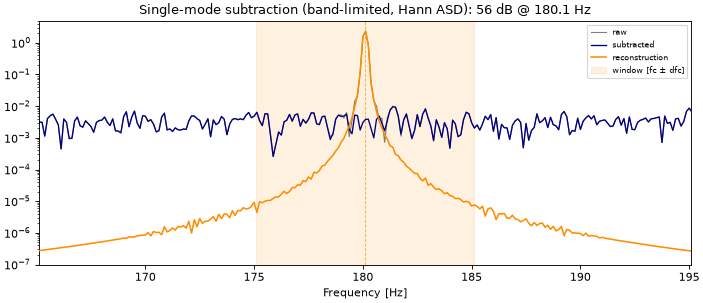

In [ ]:
# Band-limited reconstruction: clip to [fc ± 2·dfc] to erase the fc ± fs_dec
# upsampling images (~-125 dB). The shared Hann-windowed asd() from the previous
# cell shows real content, not the rectangular-window leakage skirt of the strong
# narrow peak.
recon_bl = model_single.reconstruct(rec, band_limit=True)     # images removed

asd_raw   = asd(strain)
asd_recon = asd(recon_bl)
asd_sub   = asd(strain - recon_bl)

idx_f1 = np.argmin(np.abs(freq_axis - f1))
suppression_dB = 20 * np.log10(asd_raw[idx_f1] / asd_sub[idx_f1])
print(f"Peak @ {f1} Hz: raw={asd_raw[idx_f1]:.3f}  residual={asd_sub[idx_f1]:.2e}  "
      f"-> {suppression_dB:.0f} dB suppression")
for f_img in (f1 - model_single._fs_dec, f1 + model_single._fs_dec):
    j = np.argmin(np.abs(freq_axis - f_img))
    print(f"  image @ {f_img:.1f} Hz: {20*np.log10(asd_recon[j]/asd_raw[idx_f1]):.0f} dB (band-limited away)")

# raw (back) -> subtracted (mid) -> reconstruction (front): each layer stays visible
zoom = 3 * model_single.dfc
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(freq_axis, asd_raw,   color="black",      lw=1,    alpha=0.5, zorder=1, label="raw")
ax.semilogy(freq_axis, asd_sub,   color="navy",       lw=1.2,             zorder=2, label="subtracted")
ax.semilogy(freq_axis, asd_recon, color="darkorange", lw=1.4,             zorder=3, label="reconstruction")
ax.axvspan(f1 - model_single.dfc, f1 + model_single.dfc, alpha=0.12, color="darkorange", zorder=0, label="window [fc ± dfc]")
ax.axvline(f1, ls="--", color="darkorange", lw=0.8, alpha=0.7, zorder=0)
ax.set_xlim(f1 - zoom, f1 + zoom); ax.set_ylim(1e-7, 5)
ax.set_xlabel("Frequency [Hz]")
ax.set_title(f"Single-mode subtraction (band-limited, Hann ASD): {suppression_dB:.0f} dB @ {f1} Hz")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()


---
## Step 4 — Window Masking: `fc ± dfc` Acts as a Filter

`HarmonicOscillatorModel` and `InharmonicOscillatorModel` generate a full frequency
ladder of partials. But the window `[fc ± dfc]` acts as a **mask**. Only partials
inside the window enter the state.

Partials outside the window are generated, but the model drops them silently. This is
not a limitation. It is the design: each window corrects the signal only in its own
frequency band.

To track multiple partials of the same ladder, use one window per partial. Compose
the windows in an `OscillatorBankModel`, in **INDEPENDENT** mode.


In [ ]:
from kalman.apps.resonators.oscillators import InharmonicOscillatorModel, partial_frequencies

f0_demo, B_demo, n_demo = 180.1, 0.105, 5
full_ladder = partial_frequencies(f0_demo, B_demo, n_demo)
print("Full inharmonic ladder (n=1..5):", np.round(full_ladder, 2), "Hz")

# Window centered on the 2nd partial — only that one is tracked
fc_2 = full_ladder[1]   # 2nd partial ≈ 429 Hz
model_window = InharmonicOscillatorModel("win", f0=f0_demo, fc=fc_2, dfc=10.0,
                                          n_harmonics=n_demo, B=B_demo, fs=4096.0)
print(f"\nWindow fc={fc_2:.1f} ± 10 Hz tracks: {np.round(model_window.frequencies, 2)} Hz")
print(f"  → {len(model_window.frequencies)} mode(s) in state  (others masked out)")

# Different window widths
print("\nEffect of window width on masking:")
for dfc in [5, 50, 200]:
    try:
        test_model = InharmonicOscillatorModel("test", f0=f0_demo, fc=fc_2, dfc=dfc,
                                                n_harmonics=n_demo, B=B_demo, fs=4096.0)
        print(f"  dfc={dfc:4.0f} Hz → {len(test_model.frequencies)} in-band: {np.round(test_model.frequencies, 1)} Hz")
    except ValueError as e:
        print(f"  dfc={dfc:4.0f} Hz → {e}")


Full inharmonic ladder (n=1..5): [ 189.32  429.23  753.52 1179.35 1714.5 ] Hz

Window fc=429.2 ± 10 Hz tracks: [429.23] Hz
  → 1 mode(s) in state  (others masked out)

Effect of window width on masking:
  dfc=   5 Hz → 1 in-band: [429.2] Hz
  dfc=  50 Hz → 1 in-band: [429.2] Hz
  dfc= 200 Hz → 1 in-band: [429.2] Hz


---
## Step 5 — Multiple Peaks in One Window: the FUSED Joint State

Several peaks can fall inside the same window `[fc ± dfc]`. The model then estimates
them **jointly**, as a single FUSED channel: `z = Σ ψ_i`.

The filter separates the peaks by their different precession rates:
`Δf_i = f_i − fc`.

This is the joint Kalman filter described by Moisset et al. (2025) and Mukherjee &
Finn (1999).


In [ ]:
freqs_c = [178.0, 180.1, 182.5]
amps_c = [1.0, 0.6, 0.4]
Qs_c = [1.3e4] * 3
clean_c = sum(A * np.exp(-t / (Q / (np.pi * f))) * np.cos(2 * np.pi * f * t)
              for A, f, Q in zip(amps_c, freqs_c, Qs_c))
strain_c = clean_c + 0.1 * np.random.randn(N)

model_cluster = OscillatorModel("cluster", freqs_c, fc=180.0, dfc=8.0, Q=Qs_c, fs=fs,
                                 measurement_uncertainty=0.1, process_uncertainty=1e-4)
rec_c = model_cluster.filter(strain_c, smooth=True)
amp_c = model_cluster.amplitudes(rec_c)
t_dec_c = np.linspace(0, T, amp_c.shape[0])   # state at decimated rate
print(f"n={model_cluster.n}, m={model_cluster.m}  (3 modes × 2 states each, ONE demodulated band channel)")
print(f"N_dec={amp_c.shape[0]} at fs_dec={model_cluster.fs:.1f} Hz")


n=6, m=2  (3 modes × 2 states each, ONE demodulated band channel)
N_dec=256 at fs_dec=32.0 Hz


Per-peak suppression (FUSED window):
   178.0 Hz: 68 dB
   180.1 Hz: 53 dB
   182.5 Hz: 51 dB


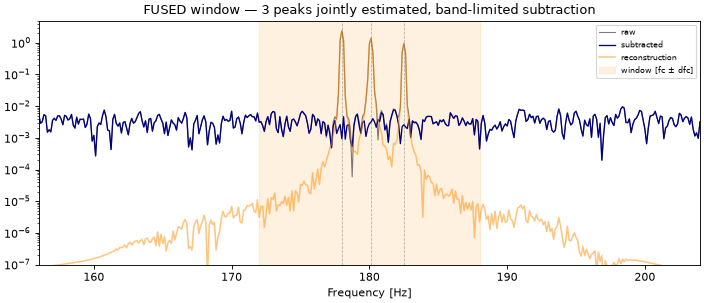

In [ ]:
# Band-limited reconstruction + Hann-windowed ASD for the FUSED cluster.
# The 3 peaks share ONE window [fc ± dfc]; they are disentangled jointly and the
# joint reconstruction is subtracted in one shot.
recon_c = model_cluster.reconstruct(rec_c, band_limit=True)
asd_raw_c, asd_rec_c, asd_sub_c = asd(strain_c), asd(recon_c), asd(strain_c - recon_c)
fc_cluster, dfc_cluster = model_cluster.fc, model_cluster.dfc

print("Per-peak suppression (FUSED window):")
for f in freqs_c:
    j = np.argmin(np.abs(freq_axis - f))
    print(f"  {f:6.1f} Hz: {20*np.log10(asd_raw_c[j] / asd_sub_c[j]):.0f} dB")

zoom = 3 * dfc_cluster
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(freq_axis, asd_raw_c, color="black",      lw=1.0, alpha=0.5,  zorder=1, label="raw")
ax.semilogy(freq_axis, asd_sub_c, color="navy",       lw=1.2,             zorder=2, label="subtracted")
ax.semilogy(freq_axis, asd_rec_c, color="darkorange", lw=1.4, alpha=0.5,  zorder=3, label="reconstruction")
ax.axvspan(fc_cluster - dfc_cluster, fc_cluster + dfc_cluster, alpha=0.12, color="darkorange", zorder=0, label="window [fc ± dfc]")
for f in freqs_c:
    ax.axvline(f, ls="--", color="gray", lw=0.7, alpha=0.6, zorder=0)
ax.set_xlim(fc_cluster - zoom, fc_cluster + zoom); ax.set_ylim(1e-7, 5)
ax.set_xlabel("Frequency [Hz]")
ax.set_title(f"FUSED window — {len(freqs_c)} peaks jointly estimated, band-limited subtraction")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()


---
## Step 6 — Harmonic and Inharmonic Ladders

A ladder model generates a candidate series of partials. It masks each window to
`[fc ± dfc]`, as described in Step 4.

Stiff wires are **inharmonic**. Their partials stretch upward as the mode number
increases:

$$f_n = n\,f_0\,\sqrt{1 + B\,n^2}, \qquad B = \frac{\pi^3 E d^4}{64\,T L^2}$$

Setting `B = 0` recovers the pure harmonic series `f_n = n·f0`. So
`HarmonicOscillatorModel` is just `InharmonicOscillatorModel` with `B = 0`.

The two plots below show:
- The partial positions.
- Their deviation from the harmonic grid.

After the plots, one `InharmonicOscillatorModel` window per partial is composed in
**INDEPENDENT** mode. Band-limited reconstruction then subtracts each partial from
the signal.


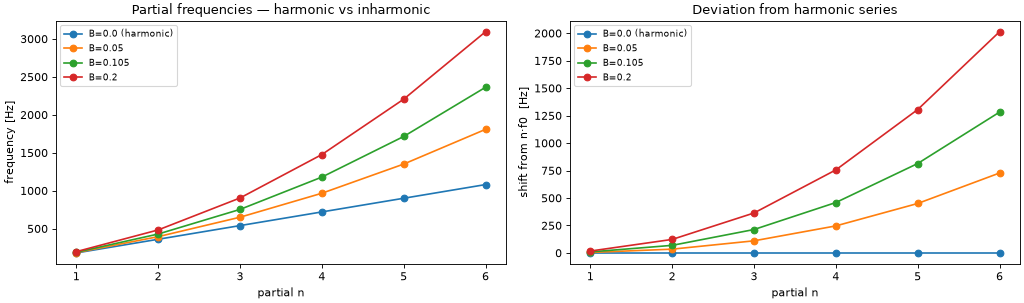

In [ ]:
from kalman.apps.resonators.oscillators import partial_frequencies

f0_ih = 180.1
n_ih  = 6
B_values = [0.0, 0.05, 0.105, 0.2]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
partial_numbers = np.arange(1, n_ih + 1)
for B in B_values:
    freqs_ih = partial_frequencies(f0_ih, B, n_ih)
    label = f"B={B}" + (" (harmonic)" if B == 0 else "")
    axes[0].plot(partial_numbers, freqs_ih, "o-", label=label)
    deviation = freqs_ih - partial_numbers * f0_ih          # shift vs ideal harmonic
    axes[1].plot(partial_numbers, deviation, "o-", label=label)

axes[0].set_xlabel("partial n"); axes[0].set_ylabel("frequency [Hz]")
axes[0].set_title("Partial frequencies — harmonic vs inharmonic"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("partial n"); axes[1].set_ylabel("shift from n·f0  [Hz]")
axes[1].set_title("Deviation from harmonic series"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


Inharmonic ladder: [189.32 429.23 753.52] Hz
  W1  fc= 189.3 Hz  tracks [189.3] Hz   ->  42 dB
  W2  fc= 429.2 Hz  tracks [429.2] Hz   ->  31 dB
  W3  fc= 753.5 Hz  tracks [753.5] Hz   ->  21 dB


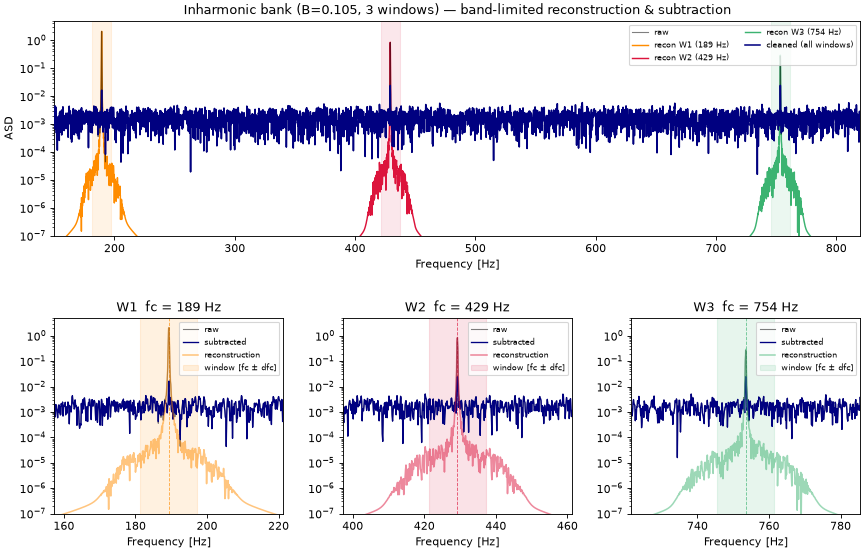

In [ ]:
# Inharmonic bank — one window per partial, INDEPENDENT; band-limited reconstruction
# reuses the shared Hann-windowed asd() defined in the single-peak cell.
from kalman.apps.resonators.oscillators import InharmonicOscillatorModel, OscillatorBankModel

B_real = 0.105
freqs_real = partial_frequencies(f0_ih, B_real, 3)
Qs_ih, A_ih = [1.3e4, 1.8e4, 2.1e4], [1.0, 0.4, 0.15]
strain_ih = 0.05 * np.random.randn(N)
for a, f, Q in zip(A_ih, freqs_real, Qs_ih):
    strain_ih += a * np.exp(-t / (Q / (np.pi * f))) * np.cos(2 * np.pi * f * t)

windows_ih = [InharmonicOscillatorModel(f"ih_{k+1}", f0=f0_ih, fc=fk, dfc=8.0,
                                        n_harmonics=3, B=B_real, Q=Qs_ih[k], fs=fs,
                                        measurement_uncertainty=0.05, process_uncertainty=1e-5)
              for k, fk in enumerate(freqs_real)]
bank_ih = OscillatorBankModel(*windows_ih)
for w, a in zip(bank_ih.windows, A_ih):
    w.initial_state([[a, 0.0]])
bank_ih.initial_state(np.vstack([w.x0 for w in bank_ih.windows]))

rec_ih  = bank_ih.filter(strain_ih, smooth=False)
recons  = bank_ih.reconstruct(rec_ih, per_window=True, band_limit=True)   # per-window, band-limited
cleaned = strain_ih - bank_ih.reconstruct(rec_ih, band_limit=True)        # full subtraction

asd_raw, asd_cln = asd(strain_ih), asd(cleaned)
colors_win = ["darkorange", "crimson", "mediumseagreen"]

print("Inharmonic ladder:", np.round(freqs_real, 2), "Hz")
for k, w in enumerate(bank_ih.windows):
    fk = w.fc; mm = (freq_axis > fk - 2) & (freq_axis < fk + 2)
    print(f"  W{k+1}  fc={fk:6.1f} Hz  tracks {np.round(w.frequencies, 1)} Hz"
          f"   ->  {20*np.log10(asd_raw[mm].max() / asd_cln[mm].max()):.0f} dB")

fig = plt.figure(figsize=(13, 8))
gs  = fig.add_gridspec(2, 3, height_ratios=[1.1, 1.0], hspace=0.40, wspace=0.26)

# Top: full-band overview (raw black z2, per-window recon z1, cleaned navy z3)
ax0 = fig.add_subplot(gs[0, :])
ax0.semilogy(freq_axis, asd_raw, color="black", alpha=0.5, lw=1.0, zorder=2, label="raw")
for k, (w, rk) in enumerate(zip(bank_ih.windows, recons)):
    ax0.semilogy(freq_axis, asd(rk), color=colors_win[k], lw=1.3, zorder=1,
                 label=f"recon W{k+1} ({w.fc:.0f} Hz)")
    ax0.axvspan(w.fc - w.dfc, w.fc + w.dfc, alpha=0.10, color=colors_win[k], zorder=0)
ax0.semilogy(freq_axis, asd_cln, color="navy", lw=1.4, zorder=3, label="cleaned (all windows)")
ax0.set_xlim(150, 820); ax0.set_ylim(1e-7, 5)
ax0.set_xlabel("Frequency [Hz]"); ax0.set_ylabel("ASD")
ax0.set_title(f"Inharmonic bank (B={B_real}, 3 windows) — band-limited reconstruction & subtraction")
ax0.legend(fontsize=7, ncol=2)

# Bottom: per-window zoom, same z-order + [fc ± dfc] shading
for k, (w, rk) in enumerate(zip(bank_ih.windows, recons)):
    ax = fig.add_subplot(gs[1, k])
    fk, dfc = w.fc, w.dfc; zoom = 4 * dfc
    ax.semilogy(freq_axis, asd_raw, color="black",        lw=1.0, alpha=0.5, zorder=1, label="raw")
    ax.semilogy(freq_axis, asd_cln, color="navy",         lw=1.2,            zorder=2, label="subtracted")
    ax.semilogy(freq_axis, asd(rk), color=colors_win[k],  lw=1.4, alpha=0.5, zorder=3, label="reconstruction")
    ax.axvspan(fk - dfc, fk + dfc, alpha=0.12, color=colors_win[k],   zorder=0, label="window [fc ± dfc]")
    ax.axvline(fk, ls="--", color=colors_win[k], lw=0.8, alpha=0.7,   zorder=0)
    ax.set_xlim(fk - zoom, fk + zoom); ax.set_ylim(1e-7, 5)
    ax.set_xlabel("Frequency [Hz]"); ax.set_title(f"W{k+1}  fc = {fk:.0f} Hz")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


---
## Step 7 — From Physical Parameters to Peak Positions

Given a wire's physical parameters, you can predict the full inharmonic partial
series before you touch any data.

Two key quantities set the series:

$$f_0 = \frac{1}{2L}\sqrt{\frac{T}{\mu}}, \quad \mu = \rho \frac{\pi d^2}{4}
\qquad \text{(transverse wave speed)}$$

$$B = \frac{\pi^3 E d^4}{64 \, T L^2}
\qquad \text{(Fletcher stiff-string inharmonicity)}$$

A **KAGRA violin-mode wire** (Type-A suspension, intermediate mass wire) has these
typical values:
- Material: steel ($E \approx 2 \times 10^{11}$ Pa, $\rho \approx 7800$ kg/m³)
- Diameter: $d \approx 0.31$ mm
- Length: $L \approx 600$ mm
- Tension: $T \approx 7$ N


Wire fundamental:     f0 = 90.87 Hz
Inharmonicity coeff:  B  = 0.0004

Predicted partial frequencies [Hz]:
  n=1: harmonic=90.87  inharmonic=90.88  (shift +0.02 Hz)
  n=2: harmonic=181.74  inharmonic=181.87  (shift +0.13 Hz)
  n=3: harmonic=272.61  inharmonic=273.04  (shift +0.44 Hz)
  n=4: harmonic=363.47  inharmonic=364.51  (shift +1.03 Hz)
  n=5: harmonic=454.34  inharmonic=456.36  (shift +2.01 Hz)


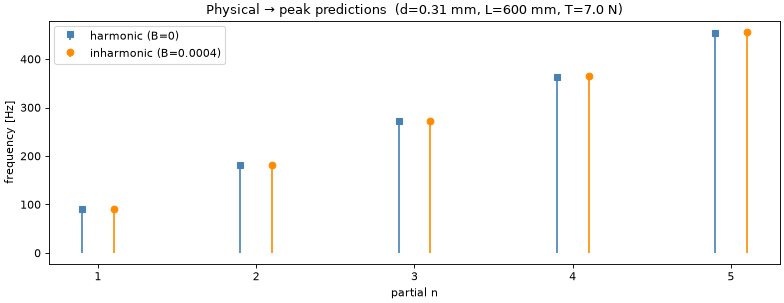


Ready to filter: InharmonicOscillatorModel(f0=90.87, fc=<partial>, B=0.0004)


In [ ]:
from kalman.apps.resonators.oscillators import wire_fundamental, wire_inharmonicity

# Steel suspension wire parameters
E   = 2e11     # Young's modulus [Pa]
rho = 7800.0   # density [kg/m³]
d   = 0.31e-3  # diameter [m]
L   = 0.600    # length [m]
T_w = 7.0      # tension [N]

f0_wire = wire_fundamental(d, L, T_w, rho)
B_wire  = wire_inharmonicity(E, d, L, T_w)
print(f"Wire fundamental:     f0 = {f0_wire:.2f} Hz")
print(f"Inharmonicity coeff:  B  = {B_wire:.4f}")

n_partials = 5
freqs_wire = partial_frequencies(f0_wire, B_wire, n_partials)
freqs_harm = partial_frequencies(f0_wire, 0.0,    n_partials)   # ideal harmonic
print("\nPredicted partial frequencies [Hz]:")
for n, (fh, fi) in enumerate(zip(freqs_harm, freqs_wire), 1):
    print(f"  n={n}: harmonic={fh:.2f}  inharmonic={fi:.2f}  (shift {fi-fh:+.2f} Hz)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.stem(np.arange(1, n_partials + 1) - 0.1, freqs_harm, linefmt="steelblue",
        markerfmt="s", basefmt=" ", label="harmonic (B=0)")
ax.stem(np.arange(1, n_partials + 1) + 0.1, freqs_wire, linefmt="darkorange",
        markerfmt="o", basefmt=" ", label=f"inharmonic (B={B_wire:.4f})")
ax.set_xlabel("partial n"); ax.set_ylabel("frequency [Hz]")
ax.set_title(f"Physical → peak predictions  (d={d*1e3:.2f} mm, L={L*1e3:.0f} mm, T={T_w} N)")
ax.legend(); plt.tight_layout(); plt.show()

# Direct pipeline: physical params → InharmonicOscillatorModel
print(f"\nReady to filter: InharmonicOscillatorModel(f0={f0_wire:.2f}, fc=<partial>, B={B_wire:.4f})")

---
## Step 8 — Fitting `(f0, B)` from Measured Peak Frequencies

Wire parameters are sometimes unknown or uncertain. In that case, fit `(f0, B)` from
measured spectral peaks. Use `OscillatorModel.fit_inharmonicity` for this.

This least-squares fit inverts the Fletcher model:

$$\text{minimise} \sum_n \left(f_n^\text{meas} - n f_0 \sqrt{1 + B n^2}\right)^2$$


True:    f0 = 90.8686 Hz,  B = 0.000355
Fitted:  f0 = 91.0513 Hz,  B = 0.000208

Peak residuals [Hz]:
  n=1: measured=91.13  fitted=91.06  residual=0.072 Hz
  n=2: measured=181.80  fitted=182.18  residual=-0.381 Hz
  n=3: measured=273.36  fitted=273.41  residual=-0.044 Hz
  n=4: measured=365.27  fitted=364.81  residual=0.456 Hz
  n=5: measured=456.24  fitted=456.44  residual=-0.200 Hz


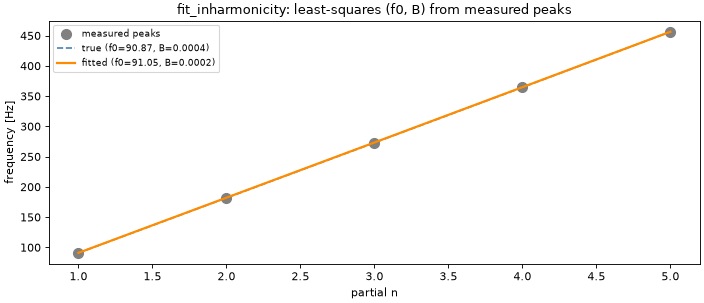

In [ ]:
# Simulate peak measurement with some noise
np.random.seed(42)
measured_peaks = freqs_wire + 0.5 * np.random.randn(n_partials)   # ±0.5 Hz jitter

f0_fit, B_fit = OscillatorModel.fit_inharmonicity(measured_peaks)
freqs_fit = partial_frequencies(f0_fit, B_fit, n_partials)

print(f"True:    f0 = {f0_wire:.4f} Hz,  B = {B_wire:.6f}")
print(f"Fitted:  f0 = {f0_fit:.4f} Hz,  B = {B_fit:.6f}")
print(f"\nPeak residuals [Hz]:")
for n, (fm, ff) in enumerate(zip(measured_peaks, freqs_fit), 1):
    print(f"  n={n}: measured={fm:.2f}  fitted={ff:.2f}  residual={fm-ff:.3f} Hz")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, n_partials + 1), measured_peaks, "o", ms=9, color="gray", label="measured peaks")
ax.plot(range(1, n_partials + 1), freqs_wire, "--", lw=1.5, color="steelblue", label=f"true (f0={f0_wire:.2f}, B={B_wire:.4f})")
ax.plot(range(1, n_partials + 1), freqs_fit, "-", lw=2, color="darkorange", label=f"fitted (f0={f0_fit:.2f}, B={B_fit:.4f})")
ax.set_xlabel("partial n"); ax.set_ylabel("frequency [Hz]")
ax.set_title("fit_inharmonicity: least-squares (f0, B) from measured peaks")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()